# Mapping magnetic_2 в одном OV 3 3 0, RF включена

Тот же разбор, что для статьи по SCT (`mapping.fox`, `SCT_mapping`, `Mapping_criterion`): сетка секступолей, зонды спина P0/P1, связь $\Delta\nu_s$ с $\xi_J$ и $\eta_1$.

Одно DA-задание: `OV 3 3 0`, без `OV 3 2 1` / `TP`. `PATHXI` — с решётки, полость — как в `delta_eq.fox` (`h=5`, `200 kV`, частота от `SPOS`), спин — после полости. Флаг `RFFLAG` решётки не используется: там частота от `fACCLEN=141` м.

Текст: [mapping_ov330.md](mapping_ov330.md). Джоб: [../jobs/mapping_ov330.fox](../jobs/mapping_ov330.fox).


## Две хроматичности

| | $\xi_B$ Берц, `TP` | $\xi_J$ частица, `MAP(5)` |
|---|---|---|
| карта | `OV 3 2 1`, энергия — параметр | `OV 3 3 0`, энергия — 6-я координата |
| физика | тюн вокруг off-energy замкнутой орбиты | лишняя длина поперечно отклонённой частицы |
| SCT-статья | ось $x$ графиков $\Delta\nu_s(\xi)$ | не использовалась |
| этот тест | не считается | `chrom_x`, `chrom_y` с `MAP(5)` до полости |

Амплитудная зависимость орбитальных тюнов не входит. `quad_Kx` — спиновый $\partial^2\nu_s/\partial x^2$ из `TSS`.


In [1]:
from pathlib import Path
from IPython.display import Image, display, Markdown
import mapping_ov330_plots as P

raw = P.load()
print(P.summary(raw))
df = P.tss_ok(raw)
display(Markdown(
    r'При нулевых секступолях $\xi_J=(-1.473,-2.230)$ — то же, что Julia Lie и delta_eq.fox. '
    r'Паспорт Берца -1.84 -1.85$ сюда не ставится.'
))


points: 23  (TSS fail MU=0 dropped: 4 of 27)
natural xi_J = (-1.472606, -2.230291)
natural xi_ell = (-1.472605, -2.230329)
natural eta0, eta1 = -0.533848, 1.017794
xi_J range x: [-10.665, 71.594]  y: [-17.130, 45.989]
natural Delta nu_s P0 (x,y,z) = -4.991573e-10, -2.349245e-09, -5.235838e-10
spin_x: R^2=0.999999  a(xi_x)=6.3812e-11  a(xi_y)=3.6030e-11  a(eta1)=4.0907e-12  d=-3.2834e-10
spin_y: R^2=0.999942  a(xi_x)=2.3056e-10  a(xi_y)=2.4770e-10  a(eta1)=-1.0763e-10  d=-1.3718e-09
spin_z: R^2=0.999981  a(xi_x)=-3.1557e-10  a(xi_y)=3.0286e-11  a(eta1)=-3.3398e-09  d=2.4594e-09


При нулевых секступолях $\xi_J=(-1.473,-2.230)$ — то же, что Julia Lie и delta_eq.fox. Паспорт Берца -1.84 -1.85$ сюда не ставится.

## $\Delta\nu_s$ зондов против $\xi_J$

Зонды как в SCT: $x=1\,\mathrm{mm}$, $y=1\,\mathrm{mm}$, $\delta=10^{-4}$ (P0). Полость — `h=5`, `200 kV`, частота от `SPOS`. Четыре узла, где `TSS` дал `MU=0` (спин-орбитальный резонанс), с графиков сняты.


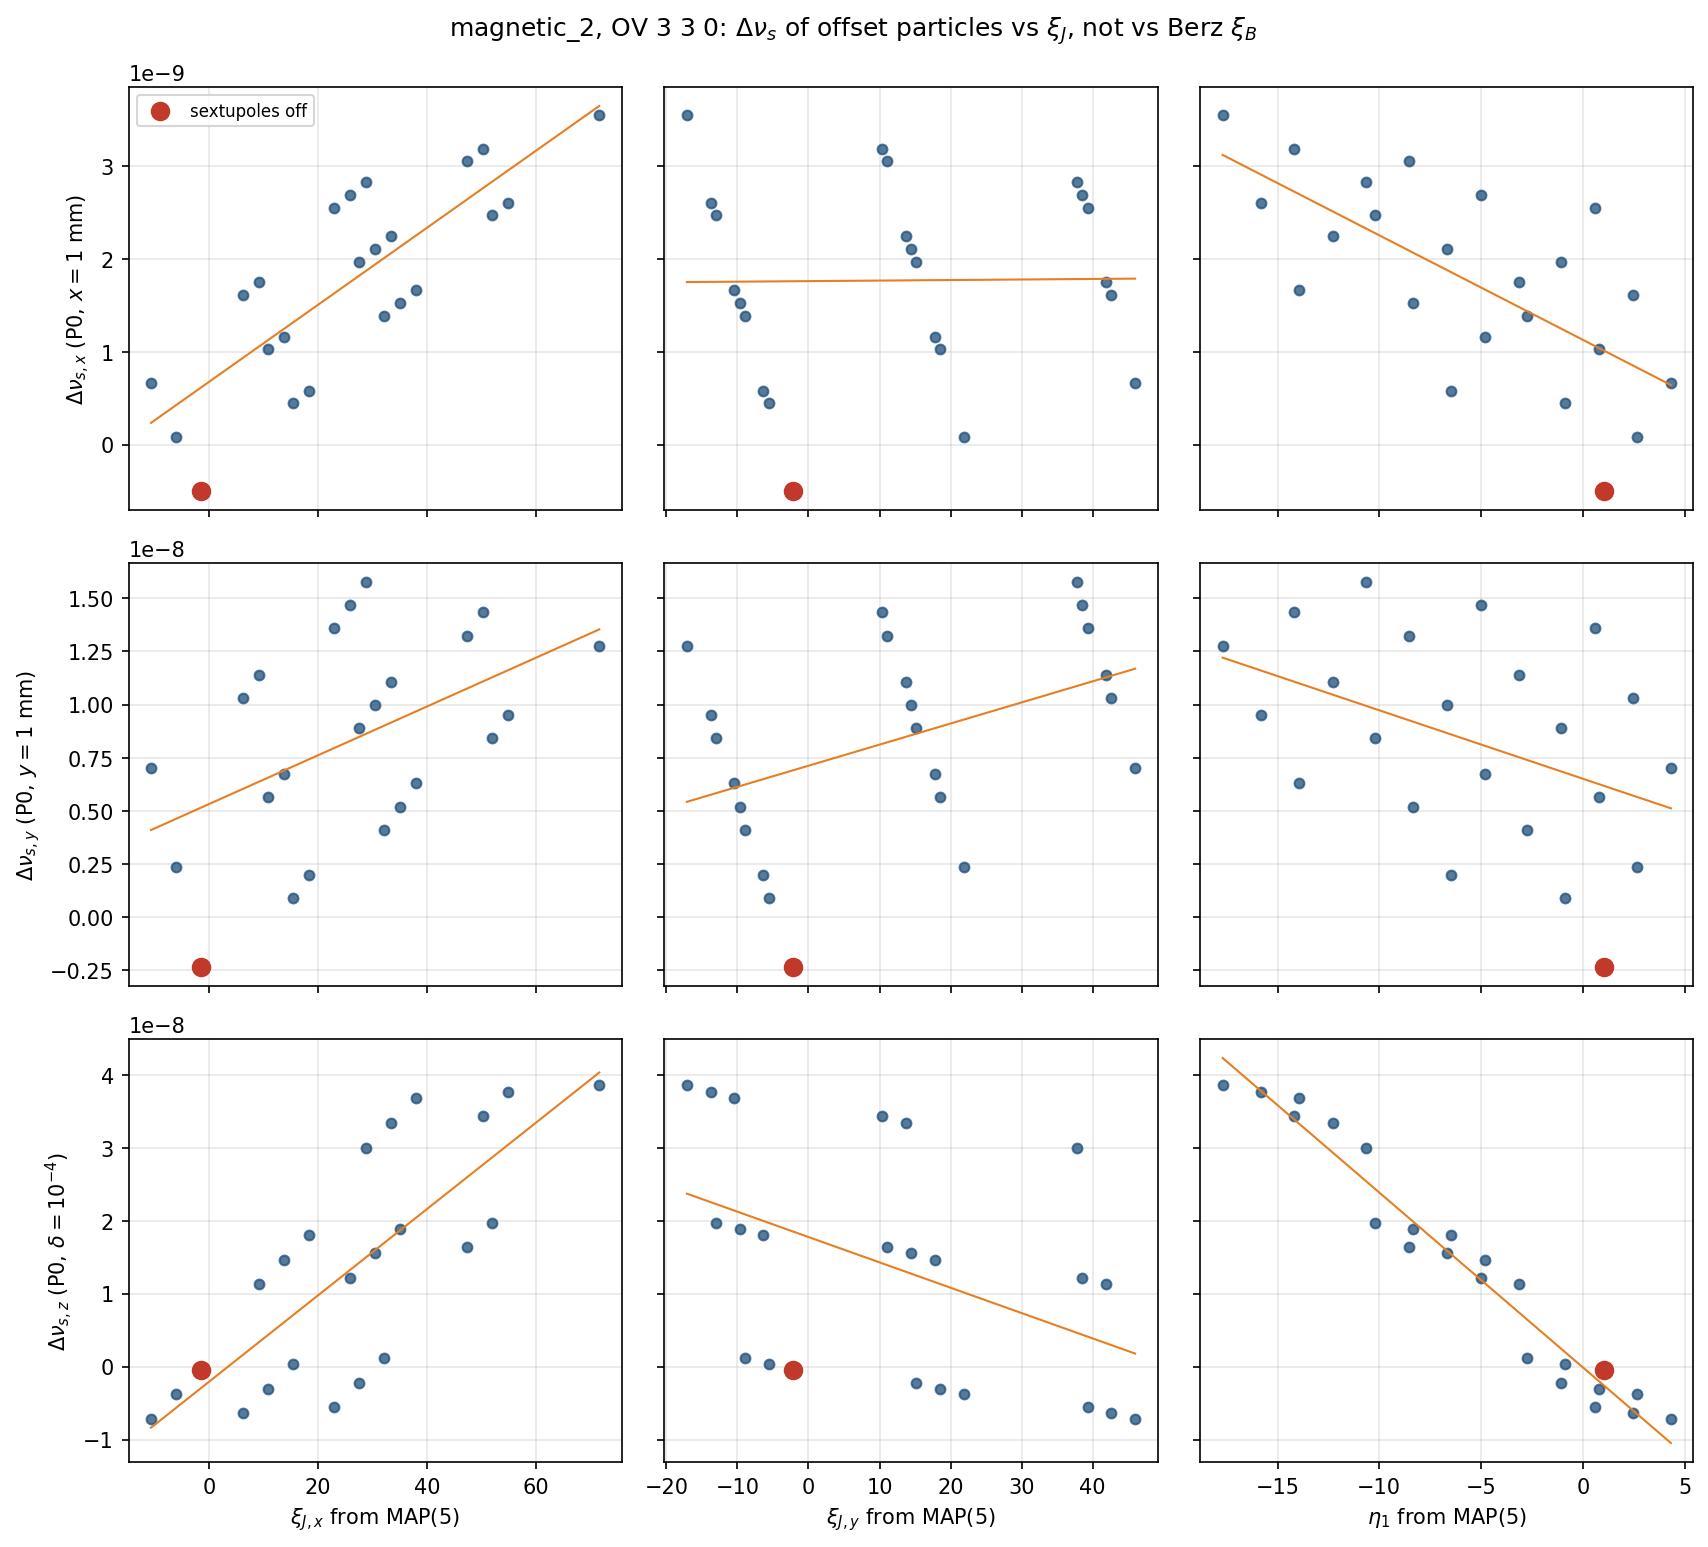

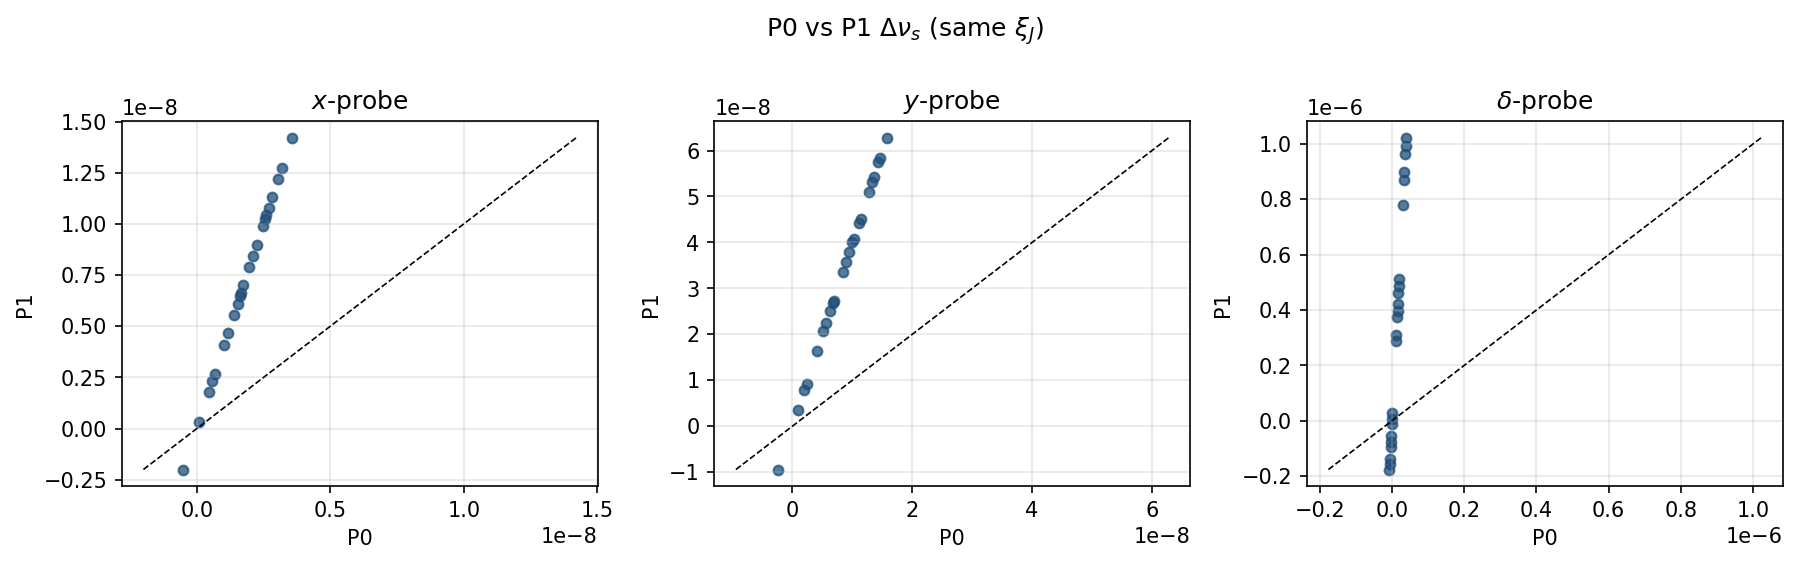

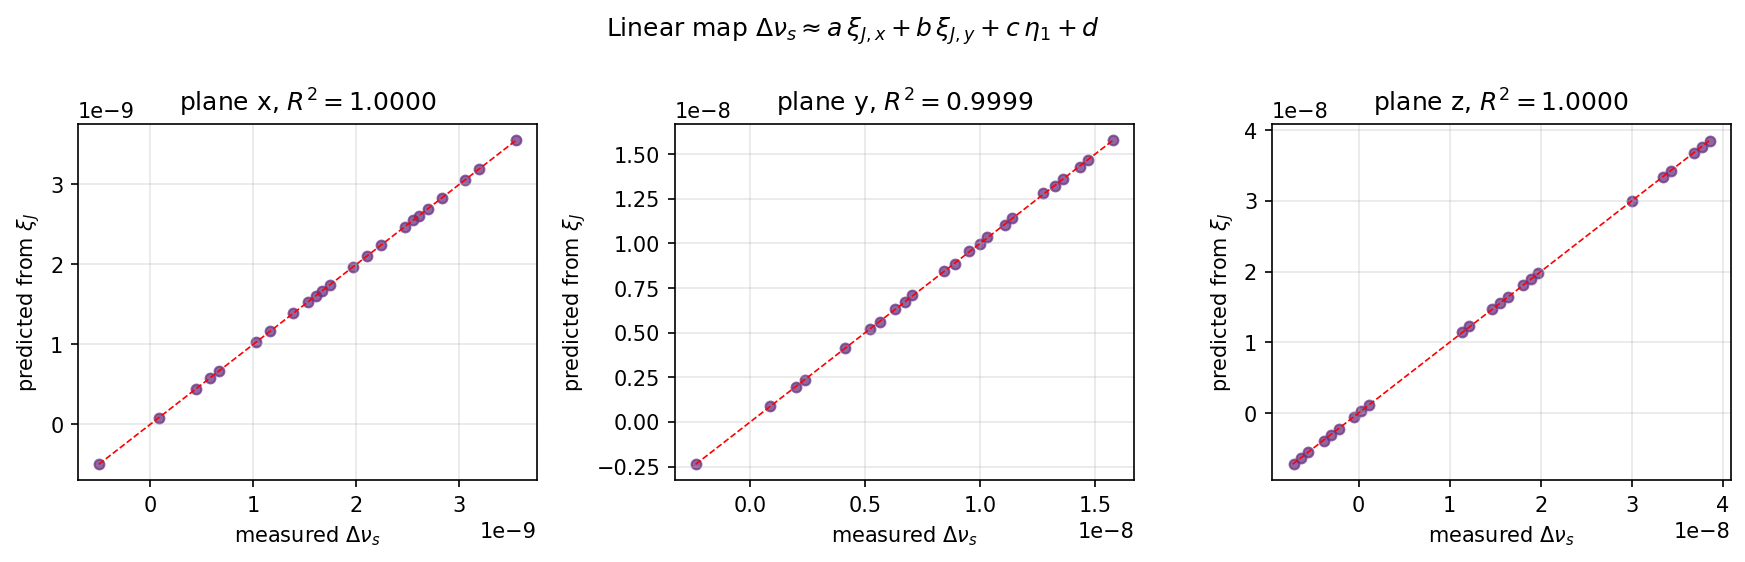

In [2]:
p1 = P.plot_dnu_vs_xi(df)
p2 = P.plot_p0_p1(df)
p3 = P.plot_link(df)
for p in (p1, p2, p3):
    display(Image(str(p)))


## Что было не так с «нелинейной моделью»

Флаг `RF=1` в `magnetic_2.fox` включает полость с частотой от `fACCLEN=141` м при кольце $C=117.39$ м. Спин зонда $\delta$ тогда сидел на константе $\sim 3.8\times 10^{-6}$, плюс в фит входили точки с `MU=0`. Отсюда $R^2\sim 0.2$–$0.4$.

С полостью `delta_eq` и без сорванных `TSS` снова $R^2\approx 1$ на этой сетке $3^3$: и $\xi_J$, и $\Delta\nu_s$ линейны по трём семействам секступолей. $\xi_B$ из `TP` на оси не ставится.
